# Vaje 2: Meta učenje in nevronske mreže v PyTorch

Cilji današnjih vaj:
- na resničnih meta podatkih ponoviti pojme s predavanj: **meta primer je učna naloga**, opisana z meta napovednimi spremenljivkami, meta cilj pa je uspešnost učnih algoritmov,
- naučiti **meta model**, ki za novo nalogo priporoči učni algoritem, in ga **pošteno ovrednotiti**,
- spoznati osnovne gradnike **PyTorch**: `nn.Module`, funkcijo izgube, optimizator, `DataLoader` in učno zanko,
- izbrati hiperparametre nevronske mreže na **validacijski množici**.

Za meta model bomo uporabili naključni gozd iz knjižnice scikit-learn. Če ga še nimate, ga namestite z `pip install scikit-learn`.

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

# Iz vaj 1
def napaka_01(y, y_hat):
    return np.mean(y != y_hat)

def k_kratna_razdelitev(n, K, rng):
    deli = np.array_split(rng.permutation(n), K)
    return [(np.concatenate(deli[:k] + deli[k + 1:]), deli[k]) for k in range(K)]

## 1. Meta učenje

Izrek o neobstoju brezplačnega kosila pravi, da noben učni algoritem ni najboljši na vseh nalogah. Na realnih nalogah pa lahko iz preteklih izkušenj sklepamo, kateri algoritem bo verjetno dober na novi nalogi. To je osnovna ideja meta učenja s predavanj.

Pri običajnem učenju je primer opazovanje (npr. kupec), pri meta učenju pa je primer **učna naloga**, podana s podatkovno množico $S_i$. Za vsako od $N$ preteklih nalog poznamo:
- **meta opis** $\tilde x_i = meta_X(S_i)$: lastnosti podatkovne množice, npr. število primerov in spremenljivk, entropijo razreda ali lastnosti naučenega odločitvenega drevesa,
- **uspešnost algoritmov** $c_{ij} = CV(\mathcal{A}_j, \lambda_j, S_i)$: napako algoritma $\mathcal{A}_j$ na nalogi $S_i$.

Iz tega sestavimo dve meta nalogi:
- **meta klasifikacija:** napovemo najboljši algoritem $j^*(S) = \arg\min_j CV(\mathcal{A}_j, \lambda_j, S)$,
- **meta regresija:** napovemo napako $c_{ij}$ posameznega algoritma.

### Podatki

V datoteki `meta_features.csv` je meta opis 52 klasifikacijskih nalog s platforme OpenML, v datoteki `meta_target.csv` pa natančnost treh algoritmov na teh nalogah: metode najbližjih sosedov (`knn`), odločitvenega drevesa (`tree`) in naivnega Bayesa (`bayes`). Natančnost pretvorimo v napako 0–1, tako da kot na predavanjih velja: manjša napaka je boljša.

In [2]:
with open("meta_features.csv") as f:
    imena_meta = f.readline().strip().split(",")[1:]          # prvi stolpec je ime naloge
X_meta = np.genfromtxt("meta_features.csv", delimiter=",", skip_header=1)[:, 1:]
naloge = np.genfromtxt("meta_target.csv", delimiter=",", skip_header=1, usecols=0, dtype=str)
algoritmi = np.array(["knn", "tree", "bayes"])
C = 1 - np.genfromtxt("meta_target.csv", delimiter=",", skip_header=1, usecols=(1, 2, 3))   # c_ij: napake 0–1

# Meta napovedne spremenljivke z manjkajočimi vrednostmi odstranimo
ok = ~np.isnan(X_meta).any(axis=0)
print("Odstranimo:", [ime for ime, o in zip(imena_meta, ok) if not o])
X_meta = X_meta[:, ok]
imena_meta = [ime for ime, o in zip(imena_meta, ok) if o]
print("X_meta:", X_meta.shape, " C:", C.shape)
print(imena_meta[:12], "...")

Odstranimo: ['num_to_cat', 'nodes_per_level.sd', 'nodes_repeated.sd', 'tree_imbalance.sd']
X_meta: (52, 45)  C: (52, 3)
['attr_conc.mean', 'attr_conc.sd', 'attr_ent.mean', 'attr_ent.sd', 'attr_to_inst', 'cat_to_num', 'class_conc.mean', 'class_conc.sd', 'class_ent', 'eq_num_attr', 'freq_class.mean', 'freq_class.sd'] ...


In [3]:
print(f"{'naloga':28s}", "  ".join(f"{a:>6s}" for a in algoritmi))
for ime, c in zip(naloge[:6], C[:6]):
    print(f"{ime:28s}", "  ".join(f"{v:6.3f}" for v in c))

naloga                          knn    tree   bayes
iris                          0.026   0.053   0.026
zoo                           0.192   0.077   0.077
wine                          0.356   0.111   0.022
hayes-roth                    0.450   0.100   0.275
fri_c3_100_50                 0.480   0.120   0.440
pwLinear                      0.120   0.180   0.160


### Meta cilj: najboljši algoritem

Meta cilj je indeks algoritma z najmanjšo napako. Pozor: pri izenačenju potrebujemo dogovorjeno pravilo. `argmin` vrne prvi najmanjši indeks, zato ima `knn` pri izenačenju prednost pred `tree`, ta pa pred `bayes`.

In [4]:
y_meta = C.argmin(axis=1)                    # j*(S_i)
print("Najboljši algoritem:", dict(zip(algoritmi.tolist(), np.bincount(y_meta).tolist())))

urejene = np.sort(C, axis=1)
print("Število nalog, kjer sta najboljša algoritma izenačena:", np.isclose(urejene[:, 0], urejene[:, 1]).sum(), "od", len(C))

Najboljši algoritem: {'knn': 24, 'tree': 18, 'bayes': 10}
Število nalog, kjer sta najboljša algoritma izenačena: 15 od 52


### Meta model in njegovo vrednotenje

Kot meta model uporabimo naključni gozd, za primerjavo pa osnovni model, ki vedno napove večinski razred učnih podatkov. Ker imamo le 52 meta primerov, uporabimo prečno preverjanje z izpuščanjem enega primera (*leave-one-out*): vsako nalogo enkrat izpustimo, meta model naučimo na ostalih in z njim napovemo izpuščeno nalogo.

Funkcija `napaka_pp` za vsako nalogo zabeleži, ali je bila izbira pravilna, in vrne povprečje po vseh nalogah.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

def napaka_pp(delitve, X, y, nov_model):
    # Vsak primer je v natanko enem validacijskem delu; zberemo njegovo napako in povprečimo.
    napake = np.zeros(len(y))
    for i_ucni, i_val in delitve:
        model = nov_model().fit(X[i_ucni], y[i_ucni])
        napake[i_val] = model.predict(X[i_val]) != y[i_val]
    return napake.mean()

gozd = lambda: RandomForestClassifier(n_estimators=200, random_state=0)
vecinski = lambda: DummyClassifier(strategy="most_frequent")

n_nalog = len(y_meta)
delitve_loo = [(np.delete(np.arange(n_nalog), i), np.array([i])) for i in range(n_nalog)]
print("Izpusti eno nalogo: napaka 0–1, osnovni model = %.3f, naključni gozd = %.3f"
      % (napaka_pp(delitve_loo, X_meta, y_meta, vecinski), napaka_pp(delitve_loo, X_meta, y_meta, gozd)))

Izpusti eno nalogo: napaka 0–1, osnovni model = 0.538, naključni gozd = 0.385


### Past: različice iste podatkovne množice

Rezultat je videti obetaven. Poglejmo pa imena nalog.

In [6]:
print(sorted(naloge.tolist(), key=str.lower))

['autoPrice', 'breast-tissue', 'datatrieve', 'fertility', 'fri_c0_100_10', 'fri_c0_100_25', 'fri_c0_100_5', 'fri_c0_100_50', 'fri_c1_100_10', 'fri_c1_100_25', 'fri_c1_100_5', 'fri_c1_100_50', 'fri_c2_100_10', 'fri_c2_100_25', 'fri_c2_100_5', 'fri_c2_100_50', 'fri_c3_100_10', 'fri_c3_100_25', 'fri_c3_100_5', 'fri_c3_100_50', 'fri_c4_100_10', 'fri_c4_100_25', 'fri_c4_100_50', 'hayes-roth', 'heart-long-beach', 'heart-switzerland', 'iriiiiiis', 'iris', 'Iris', 'iris-example', 'iris_reproduced', 'iris_test_upload', 'JuanFeldmanIris', 'kc1-binary', 'kc1-top5', 'KnuggetChase3', 'KungChi3', 'MindCave2', 'MyIris', 'parkinsons', 'planning-relax', 'pwLinear', 'robot-failures-lp4', 'robot-failures-lp5', 'Smartphone-Based_Recognition_of_Human_Activities', 'transplant', 'triazines', 'TuningSVMs', 'visualizing_environmental', 'wine', 'wisconsin', 'zoo']


Med nalogami je 19 različic sintetičnega generatorja `fri_c*` (različno število primerov in spremenljivk) in 8 kopij podatkov Iris, ki so jih uporabniki na OpenML naložili pod različnimi imeni. Na predavanjih smo slišali: **različic iste izvorne podatkovne množice ne razdelimo med učenje in vrednotenje meta modela**. Sicer meta model oceni le, kako dobro prepozna znano nalogo, ne pa, kako dobro bo deloval na novi.

Naloge zato združimo v skupine po izvorni podatkovni množici in uporabimo prečno preverjanje z **izpuščanjem ene skupine** (*leave-one-group-out*).

Skupine so različno velike (od 1 do 19 nalog). Če bi povprečili napake po delih, bi imela skupina z eno nalogo enako težo kot skupina `fri_c` z 19 nalogami. Zato napako računamo na vseh nalogah hkrati, kar je enako povprečju po delih, uteženemu s številom nalog v delu (prosojnica o prečnem preverjanju).

In [7]:
def skupina(ime):
    # Različice iste izvorne podatkovne množice združimo v eno skupino.
    ime = ime.lower()
    if "iri" in ime:                           # iris, Iris, MyIris, iriiiiiis, iris_reproduced, ...
        return "iris"
    if ime.startswith("heart"):                # heart-long-beach, heart-switzerland
        return "heart"
    return re.sub(r"[_\-]?\d.*$", "", ime)     # fri_c3_100_50 -> fri_c, kc1-top5 -> kc

skupine = np.array([skupina(ime) for ime in naloge])
imena_skupin, velikosti = np.unique(skupine, return_counts=True)
print(len(imena_skupin), "skupin, največje:", sorted(zip(velikosti.tolist(), imena_skupin.tolist()), reverse=True)[:5])

delitve_logo = [(np.where(skupine != s)[0], np.where(skupine == s)[0]) for s in imena_skupin]
print("Izpusti eno skupino: napaka 0–1, osnovni model = %.3f, naključni gozd = %.3f"
      % (napaka_pp(delitve_logo, X_meta, y_meta, vecinski), napaka_pp(delitve_logo, X_meta, y_meta, gozd)))

24 skupin, največje: [(19, 'fri_c'), (8, 'iris'), (2, 'robot-failures-lp'), (2, 'kc'), (2, 'heart')]


Izpusti eno skupino: napaka 0–1, osnovni model = 0.692, naključni gozd = 0.712


Ko meta model ovrednotimo pošteno, je napaka bistveno večja, meta model pa ni več boljši od osnovnega. Pri 24 različnih izvornih nalogah je preprosto premalo izkušenj, da bi se meta model naučil, kateri algoritem ustreza kateri vrsti nalog. Zato se meta učenje v praksi opira na zbirke tisočih poskusov, kot je OpenML.

### ✏️ Za doma — Naloga 1: meta učenje

**1.1** Napišite funkcijo `k_kratna_razdelitev_skupine(skupine, K, rng)`, ki naključno razdeli **skupine** (ne posameznih nalog) na $K$ delov in vrne seznam parov `(i_ucni, i_val)` kot `k_kratna_razdelitev` iz vaj 1. Preverite, da nobena skupina ni hkrati v učnem in validacijskem delu. Nato za osnovni model in naključni gozd primerjajte napako 5-kratnega prečnega preverjanja z navadno razdelitvijo in z razdelitvijo po skupinah. Ker je rezultat odvisen od delitve, poskus ponovite z 20 različnimi semeni in izpišite povprečje in standardni odklon.
Namig: `np.unique`, `rng.permutation`, `np.array_split`, `np.isin`.

**1.2** Meta regresija: za vsak algoritem $\mathcal{A}_j$ naučite meta model (`sklearn.ensemble.RandomForestRegressor`), ki napoveduje njegovo napako $c_{ij}$. Uporabite delitve `delitve_logo`, zberite napovedi za vse naloge in za vsak algoritem izračunajte $R^2$. Napako katerega algoritma je najlažje napovedati?

**1.3** Ali priporočilo meta modela res pomaga?

Do zdaj smo meta model ocenjevali z napako 0–1, torej s tem, kako pogosto pravilno napove najboljši algoritem. Za uporabnika pa je pomembneje, kako dober je algoritem, ki ga dobi. Če meta model npr. priporoči drevo z napako 0,15, najboljši algoritem pa ima napako 0,12, smo izgubili le 0,03. Na predavanjih smo to povedali tako: dobra napoved meta cilja mora pomagati tudi pri reševanju nove naloge.

Primerjajte štiri načine izbire algoritma za nalogo $S_i$:
1. **meta klasifikator** (naključni gozd iz razdelka 1): izberemo algoritem, ki ga napove,
2. **meta regresija** iz 1.2: izberemo algoritem z najmanjšo napovedano napako,
3. **brez meta učenja**: vedno izberemo algoritem z najmanjšo povprečno napako na učnih nalogah,
4. **orakelj**: izberemo pravi najboljši algoritem $j^*(S_i)$. V praksi to ni mogoče, pove pa, kako dobri bi lahko bili.

Pri načinih 1–3 uporabite delitve `delitve_logo`, tako da algoritem za nalogo $S_i$ izberemo le na podlagi drugih skupin. Za vsak način izpišite povprečno napako izbranih algoritmov $\frac{1}{N}\sum_{i} c_{i\hat{j}_i}$, kjer je $\hat{j}_i$ algoritem, izbran za nalogo $S_i$.

**Vprašanja:**
- Kateri način je najboljši? Ali se meta učenje na teh podatkih splača?
- Za meta klasifikator in meta regresijo izračunajte še napako 0–1 glede na `y_meta`. Zakaj je lahko napaka 0–1 visoka, povprečna napaka izbranih algoritmov pa vseeno nizka? (Namig: spomnite se izenačenj.)

**1.4 (dodatno)** Naučite naključni gozd na vseh nalogah in narišite stolpčni diagram pomembnosti meta napovednih spremenljivk (atribut `feature_importances_`). Katerih 5 je najpomembnejših? Kaj opisujejo?

In [8]:
# 1.1: Skupinsko in navadno 5-kratno precno preverjanje
def k_kratna_razdelitev_skupine(skupine, K, rng):
    skupine = np.asarray(skupine)
    imena = np.unique(skupine)
    if not 2 <= K <= len(imena):
        raise ValueError("K mora biti med 2 in stevilom skupin.")
    # Premesamo skupine; vse naloge iste skupine ostanejo skupaj.
    deli = np.array_split(rng.permutation(imena), K)
    delitve = []
    for val_skupine in deli:
        maska = np.isin(skupine, val_skupine)
        i_ucni, i_val = np.flatnonzero(~maska), np.flatnonzero(maska)
        assert not np.intersect1d(skupine[i_ucni], skupine[i_val]).size
        delitve.append((i_ucni, i_val))
    # Vsaka naloga mora biti v validacijskem delu natanko enkrat.
    assert np.array_equal(np.sort(np.concatenate([v for _, v in delitve])),
                          np.arange(len(skupine)))
    return delitve

rezultati_11 = np.empty((20, 2, 2))  # seme, vrsta delitve, model
for seme in range(20):
    delitve_nav = k_kratna_razdelitev(n_nalog, 5, np.random.default_rng(seme))
    delitve_sk = k_kratna_razdelitev_skupine(skupine, 5, np.random.default_rng(seme))
    for d, delitve in enumerate((delitve_nav, delitve_sk)):
        for m, nov_model in enumerate((vecinski, gozd)):
            # napaka_pp povpreci po nalogah, tudi pri razlicno velikih delih.
            rezultati_11[seme, d, m] = napaka_pp(delitve, X_meta, y_meta, nov_model)

print("Preverjeno: skupine se ne prekrivajo; vsaka naloga je enkrat v validaciji.")
print(f"{'Razdelitev':18s} {'Model':18s} {'Povprecje':>10s} {'Std. odklon':>12s}")
for d, ime_delitve in enumerate(("Navadna", "Po skupinah")):
    for m, ime_modela in enumerate(("Osnovni", "Nakljucni gozd")):
        vrednosti = rezultati_11[:, d, m]
        # ddof=1: vzorcni standardni odklon cez 20 razlicnih semen.
        print(f"{ime_delitve:18s} {ime_modela:18s} {vrednosti.mean():10.3f} {vrednosti.std(ddof=1):12.3f}")
print("Odklon opisuje obcutljivost na delitev; ponovitve uporabljajo iste podatke.")


Preverjeno: skupine se ne prekrivajo; vsaka naloga je enkrat v validaciji.
Razdelitev         Model               Povprecje  Std. odklon
Navadna            Osnovni                 0.538        0.000
Navadna            Nakljucni gozd          0.404        0.031
Po skupinah        Osnovni                 0.712        0.052
Po skupinah        Nakljucni gozd          0.617        0.104
Odklon opisuje obcutljivost na delitev; ponovitve uporabljajo iste podatke.


In [9]:
# 1.2: Napoved napake vsakega algoritma na nevideni skupini
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

C_hat = np.full_like(C, np.nan)
for i_ucni, i_val in delitve_logo:
    for j in range(len(algoritmi)):
        # Locen regresor za vsak algoritem; validacijske skupine ne vidi.
        regresor = RandomForestRegressor(n_estimators=200, random_state=0)
        regresor.fit(X_meta[i_ucni], C[i_ucni, j])
        C_hat[i_val, j] = regresor.predict(X_meta[i_val])
assert np.isfinite(C_hat).all()
# R^2 izracunamo na vseh napovedih skupaj, ne na posameznih majhnih skupinah.
r2 = np.array([r2_score(C[:, j], C_hat[:, j]) for j in range(len(algoritmi))])
for algoritem, ocena in zip(algoritmi, r2):
    print(f"{algoritem:6s}: R^2 = {ocena:.3f}")
print("Najlazje napovemo napako:", algoritmi[r2.argmax()])
print("R^2 < 0 pomeni slabsi rezultat od konstante, enake povprecju pravega cilja.")


knn   : R^2 = 0.026
tree  : R^2 = 0.534
bayes : R^2 = 0.112
Najlazje napovemo napako: tree
R^2 < 0 pomeni slabsi rezultat od konstante, enake povprecju pravega cilja.


In [10]:
# 1.3: Kaksno napako dejansko doseze izbrani algoritem?
izbira_klas = np.full(n_nalog, -1, dtype=int)
izbira_osnovna = np.full(n_nalog, -1, dtype=int)
for i_ucni, i_val in delitve_logo:
    model = gozd().fit(X_meta[i_ucni], y_meta[i_ucni])
    izbira_klas[i_val] = model.predict(X_meta[i_val])
    # Najboljsi stalni algoritem izberemo samo na ucnih nalogah tega dela.
    izbira_osnovna[i_val] = C[i_ucni].mean(axis=0).argmin()

# Uporabimo ze shranjene napovedi regresorjev iz istega LOGO preverjanja.
izbira_reg = C_hat.argmin(axis=1)
izbire = {"Meta klasifikator": izbira_klas,
          "Meta regresija": izbira_reg,
          "Brez meta ucenja": izbira_osnovna,
          "Orakelj": y_meta}
povprecne_napake = {}
print(f"{'Nacin':20s} {'Napaka izbranih':>16s} {'Napaka 0-1':>12s} {'Razlika do oraklja':>18s}")
napaka_oraklja = C[np.arange(n_nalog), y_meta].mean()
for ime, izbira in izbire.items():
    # Indeksiranje iz vsake vrstice C vzame napako izbranega algoritma.
    napaka = C[np.arange(n_nalog), izbira].mean()
    povprecne_napake[ime] = napaka
    print(f"{ime:20s} {napaka:16.4f} {napaka_01(y_meta, izbira):12.3f} {napaka - napaka_oraklja:18.4f}")
prakticni = [ime for ime in izbire if ime != "Orakelj"]
print("Najboljsi izvedljivi nacin:", min(prakticni, key=povprecne_napake.get))
for ime in ("Meta klasifikator", "Meta regresija"):
    izboljsanje = povprecne_napake["Brez meta ucenja"] - povprecne_napake[ime]
    print(f"{ime}: izboljsanje glede na izbiro brez meta ucenja = {izboljsanje:.4f}")
print("Pozitivno izboljsanje pomeni korist na teh podatkih; majhna razlika ni dokaz splosne prednosti.")
print("Orakelj doseze najmanjso mozno napako med temi tremi algoritmi.")
print("Napaka 0-1 kaznuje vsako drugo izbiro enako, tudi izenacen algoritem.")
print("Zato je lahko visoka, ceprav izberemo algoritem z enako ali le malo vecjo napako.")


Nacin                 Napaka izbranih   Napaka 0-1 Razlika do oraklja
Meta klasifikator              0.2588        0.712             0.0618
Meta regresija                 0.2440        0.596             0.0470
Brez meta ucenja               0.2679        0.865             0.0709
Orakelj                        0.1970        0.000             0.0000
Najboljsi izvedljivi nacin: Meta regresija
Meta klasifikator: izboljsanje glede na izbiro brez meta ucenja = 0.0091
Meta regresija: izboljsanje glede na izbiro brez meta ucenja = 0.0238
Pozitivno izboljsanje pomeni korist na teh podatkih; majhna razlika ni dokaz splosne prednosti.
Orakelj doseze najmanjso mozno napako med temi tremi algoritmi.
Napaka 0-1 kaznuje vsako drugo izbiro enako, tudi izenacen algoritem.
Zato je lahko visoka, ceprav izberemo algoritem z enako ali le malo vecjo napako.


Pet najpomembnejsih meta znacilk:
joint_ent.sd                                  0.0654
attr_ent.sd                                   0.0584
class_conc.sd                                 0.0515
class_conc.mean                               0.0434
attr_conc.mean                                0.0414


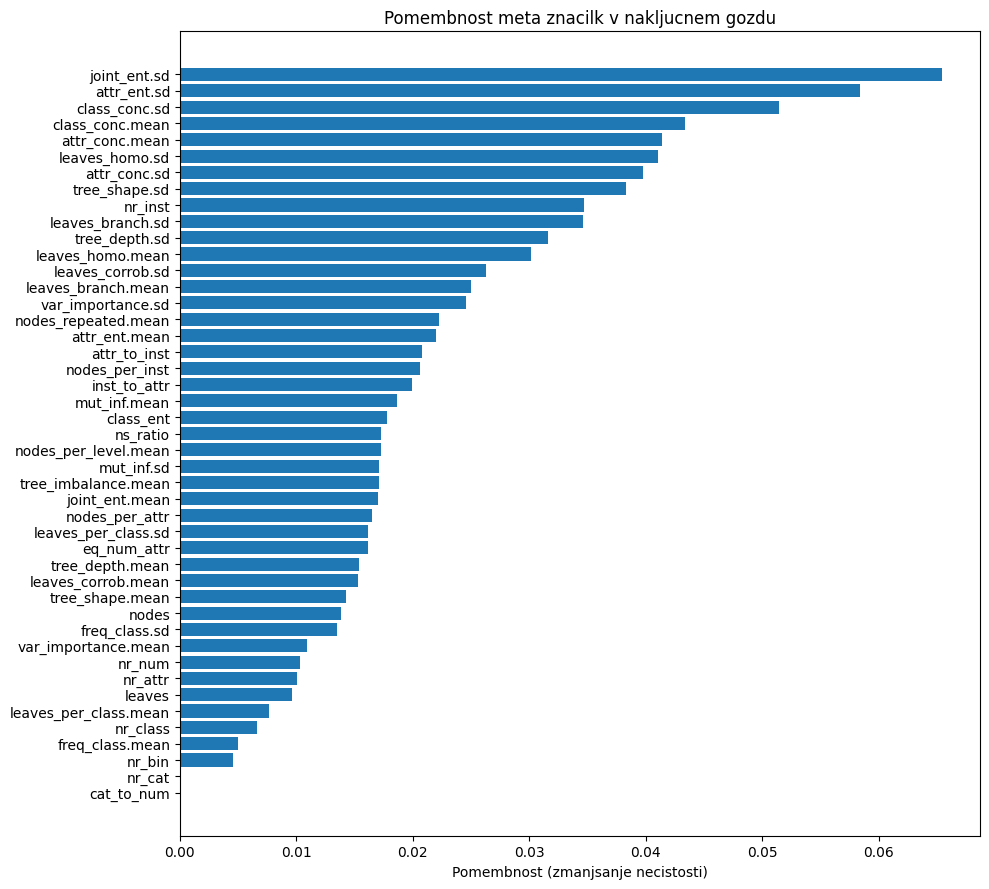

Pomembnosti opisujejo nauceni model; ne dokazujejo vzrocnosti.
Korelirane znacilke si lahko delijo pomembnost, zvezne pa so lahko precenjene.


In [11]:
# 1.4 (dodatno): Pomembnost meta znacilk
model_vsi = gozd().fit(X_meta, y_meta)
pomembnosti = model_vsi.feature_importances_
vrstni_red = np.argsort(pomembnosti)[::-1]
print("Pet najpomembnejsih meta znacilk:")
for j in vrstni_red[:5]:
    print(f"{imena_meta[j]:45s} {pomembnosti[j]:.4f}")

fig, ax = plt.subplots(figsize=(10, max(5, len(imena_meta) * 0.20)))
ax.barh(np.arange(len(imena_meta)), pomembnosti[vrstni_red])
ax.set_yticks(np.arange(len(imena_meta)), np.array(imena_meta)[vrstni_red])
ax.invert_yaxis()
ax.set(xlabel="Pomembnost (zmanjsanje necistosti)", title="Pomembnost meta znacilk v nakljucnem gozdu")
plt.tight_layout()
plt.show()
print("Pomembnosti opisujejo nauceni model; ne dokazujejo vzrocnosti.")
print("Korelirane znacilke si lahko delijo pomembnost, zvezne pa so lahko precenjene.")


### Razlaga rezultatov naloge 1

**1.1:** Navadna razdelitev daje gozdu napako **0,404 ± 0,031**, skupinska pa **0,617 ± 0,104** (povprečje ± vzorčni standardni odklon čez 20 semen). Navadno preverjanje je optimistično, ker se različice iste izvorne množice pojavijo tako med učenjem kot med vrednotenjem. Skupinske delitve so tudi bolj spremenljive. Osnovni model doseže 0,538 oziroma 0,712. Odkloni opisujejo spremembe med delitvami istih podatkov, ne negotovosti na neodvisnih novih zbirkah.

**1.2:** Najlažje napovemo napako drevesa (`tree`, R² = **0,534**); za `bayes` je R² = 0,112, za `knn` pa 0,026.

**1.3:** Najboljši izvedljivi način je meta regresija (povprečna napaka **0,2440**), sledijo meta klasifikator (0,2588) in izbira brez meta učenja (0,2679). Meta učenje torej na teh podatkih pomaga: regresija zmanjša napako za približno **2,38 odstotne točke**, klasifikator pa za 0,91. Pri majhnem številu izvornih skupin to še ne zagotavlja prednosti na drugih podatkih. Orakelj doseže 0,1970. Napaki izbire 0–1 sta kljub temu visoki (0,596 in 0,712), ker štejeta vsako izbiro drugega algoritma kot napačno, tudi kadar sta algoritma izenačena ali se njuni napaki zelo malo razlikujeta.

**1.4:** Pet najpomembnejših značilk opisuje entropijo in povezanost spremenljivk:

- `joint_ent.sd`: standardni odklon skupne entropije atributa in razreda čez atribute; opisuje razlike v njuni skupni negotovosti.
- `attr_ent.sd`: standardni odklon entropije atributov; pove, kako različno negotove so njihove porazdelitve.
- `class_conc.sd`: standardni odklon mer koncentracije oziroma povezanosti med atributi in razredom; opisuje razlike v njihovi povezanosti s ciljem.
- `class_conc.mean`: povprečna koncentracija oziroma povezanost med atributi in razredom.
- `attr_conc.mean`: povprečna koncentracija oziroma povezanost med pari atributov; opisuje njihovo medsebojno odvisnost.

`mean` pomeni povprečje, `sd` standardni odklon. Pomembnosti temeljijo na zmanjšanju nečistosti v gozdu, naučenem na vseh nalogah, zato služijo razlagi tega modela in niso dodatna ocena njegove uspešnosti na novih nalogah.


## 2. Nevronske mreže v PyTorch

### Podatki

Imamo 2708 znanstvenih člankov s področja strojnega učenja. Vsak članek je opisan z vrečo besed (*bag of words*): 1433 spremenljivk z vrednostjo 1, če se beseda v članku pojavi, in 0 sicer. Vsak članek spada v eno od 7 področij. Učnih primerov je zelo malo: samo 140 (20 na področje), podanih z masko v `podatki1_train_mask.txt`. Od preostalih člankov jih 500 naključno izberemo za validacijsko množico, ostali so testna množica.

In [ ]:
X = np.loadtxt("podatki1_x.txt", dtype=np.float32)
y = np.loadtxt("podatki1_y.txt").astype(int)
ucni = np.loadtxt("podatki1_train_mask.txt").astype(bool)

rng = np.random.default_rng(0)
i_train = np.where(ucni)[0]
ostali = rng.permutation(np.where(~ucni)[0])
i_val, i_test = ostali[:500], ostali[500:]

print("X:", X.shape, " povprečno besed na članek:", X.sum(axis=1).mean().round(1))
print("učnih:", len(i_train), " validacijskih:", len(i_val), " testnih:", len(i_test))
print("razredi (učna):", np.bincount(y[i_train]), " razredi (vsi):", np.bincount(y))

Ker so vsi razredi v učni množici enako pogosti, osnovni model z večinskim razredom tu ni smiseln. Za primerjavo vzamemo naključno ugibanje: vsak razred napovemo z verjetnostjo 1/7. Ne glede na porazdelitev razredov na testni množici je verjetnost pravilne napovedi $\sum_k p_k \cdot \frac{1}{7} = \frac{1}{7}$, pričakovana napaka pa $1 - 1/7 \approx 0{,}857$. Pozor: porazdelitev razredov v vseh podatkih je zelo neenakomerna (najpogostejši razred obsega 30 % člankov). Model, ki bi vedno napovedal ta razred, bi imel napako okoli 0,70, a tega iz učnih podatkov ne moremo vedeti.

### Od numpy k tenzorjem

Polja numpy pretvorimo v tenzorje s `torch.from_numpy`, ki ohrani podatkovni tip. Vhodi naj bodo `float32` (privzeti tip za nevronske mreže), razredi pa celoštevilski `int64` (`torch.long`), saj jih funkcija izgube uporabi kot indekse.

In [ ]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

Xt = torch.from_numpy(X)
yt = torch.from_numpy(y)
print(Xt.dtype, yt.dtype)

### Od vaj 1 do `nn.Module`

Na vajah 1 smo linearno regresijo učili z gradientnim spustom, ki smo ga sami sprogramirali. Pri nevronskih mrežah uporabimo gradnike PyTorch, učna zanka pa ostane enaka.

| vaje 1 | danes |
|---|---|
| parametra `w`, `b` z `requires_grad=True` | plasti `torch.nn.Linear`, ki hranijo uteži in začetne vrednosti |
| napoved `Xt @ w + b` | `model(x)`, ki pokliče metodo `forward` |
| izguba `((...) ** 2).mean()` | prečna entropija `torch.nn.CrossEntropyLoss()` |
| `torch.optim.SGD([w, b], lr=0.1)` | `torch.optim.Adam(model.parameters(), lr=0.01)` |
| vsi podatki naenkrat | učenje v naborih (*batches*) z `DataLoader` |

Argument `lr` je stopnja učenja $\eta$. Adam je optimizator s predavanj, ki uporablja glajeni gradient in glajeni kvadrat gradienta.

### Mreža

Mrežo zapišemo kot razred, ki deduje od `torch.nn.Module`. V `__init__` ustvarimo plasti s parametri, v `forward` pa zapišemo izračun od vhodne do izhodne plasti:
- `torch.nn.Linear(n_vhodov, n_izhodov)`: polno povezana plast, ki izračuna stanja nevronov $v^{(l)} = W^{(l)} \tilde y^{(l-1)}$. Uteži z začetno vrednostjo PyTorch ne hrani v prvem stolpcu $W^{(l)}$ kot na predavanjih, ampak posebej (`lin.weight` in `lin.bias`).
- `F.relu`: funkcija aktivacije $\varphi_{ReLU}(v) = \max(0, v)$. Brez nelinearne aktivacije bi bilo zaporedje linearnih plasti le en linearni model.
- `F.dropout`: med učenjem naključno izniči delež `p` izhodov nevronov in s tem zmanjša preprileganje (na predavanjih ga nismo obravnavali). Z `training=self.training` poskrbimo, da je med testiranjem ta sloj izklopljen.

Naša mreža ima eno skrito plast ($L = 1$) širine $n_1$ = `n_skritih` in izhodno plast s $C = 7$ nevroni, po enim za vsak razred. Na predavanjih ima izhodna plast pri klasifikaciji funkcijo aktivacije softmax, $\pi_k = e^{v_k} / \sum_{a=1}^{C} e^{v_a}$, izguba pa je prečna entropija $L_{CE}(y, \pi) = -\ln \pi_a$, kjer je $c_a$ pravi razred. V PyTorch softmax ni del modela: `forward` vrne stanja izhodne plasti $v^{(L+1)}$ (v PyTorch jim pravimo **logiti**), `CrossEntropyLoss` pa softmax in prečno entropijo izračuna skupaj, kar je numerično stabilnejše. Zato na izhod **ne damo** funkcije aktivacije, sicer bi softmax uporabili dvakrat.

In [ ]:
class MLP(torch.nn.Module):
    def __init__(self, n_vhodov, n_skritih, n_razredov, p_dropout=0.5):
        super().__init__()
        self.lin1 = torch.nn.Linear(n_vhodov, n_skritih)
        self.lin2 = torch.nn.Linear(n_skritih, n_razredov)
        self.p_dropout = p_dropout

    def forward(self, x):
        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=self.p_dropout, training=self.training)
        return self.lin2(x)                     # stanja izhodne plasti (logiti), brez softmaxa

torch.manual_seed(0)
model = MLP(X.shape[1], 64, 7)
print(model)
print("Število parametrov:", sum(p.numel() for p in model.parameters()))

with torch.no_grad():
    z = model(Xt[:3])
print("Oblika izhoda:", z.shape)                       # (3, 7): stanje izhodnega nevrona za vsak razred
print(F.softmax(z, dim=1).round(decimals=2))           # verjetnosti razredov π_k; vsaka vrstica se sešteje v 1

Mreža ima več kot 90 000 parametrov, učnih primerov pa le 140. Pričakujemo torej močno preprileganje.

### Učenje v naborih (*batches*)

Kot na predavanjih gradienta ne računamo na vseh učnih primerih naenkrat, ampak na naborih velikosti $b$. **Epoha** je en prehod čez učne podatke: indekse premešamo, jih razdelimo v disjunktne nabore in vsak primer uporabimo natanko enkrat. Manjši nabor pomeni manj dela na korak in več šuma v gradientu, večji pa omogoča učinkovitejše vzporedne izračune. `DataLoader` naredi prav to: podatke razdeli v nabore velikosti `batch_size`, s `shuffle=True` pa jih v vsaki epohi premeša. Zadnji nabor je lahko manjši (pri nas $140 = 4 \cdot 32 + 12$).

In [ ]:
ucni_nabori = DataLoader(TensorDataset(Xt[i_train], yt[i_train]), batch_size=32, shuffle=True)
x_nabor, y_nabor = next(iter(ucni_nabori))
print("Naborov na epoho:", len(ucni_nabori), " oblika nabora:", x_nabor.shape, y_nabor.shape)

### Učna zanka

Koraki so enaki kot na vajah 1: ponastavimo gradiente, izračunamo napoved in izgubo, z vzvratnim razširjanjem napake izračunamo gradiente (`backward`) in posodobimo parametre (`step`). Za softmax in prečno entropijo je signal napake v izhodni plasti $\delta^{(L+1)}_k = \pi_k - t_k$, kot smo izpeljali na predavanjih. PyTorch ta signal in vse nadaljnje gradiente izračuna samodejno. Novo je le dvoje:
- `model.train()` in `model.eval()` vklopita oziroma izklopita dropout,
- pri vrednotenju uporabimo `torch.no_grad()`, saj gradientov ne potrebujemo.

Napovedani razred je $c_{\arg\max_k \pi_k}$. Softmax ohranja vrstni red stanj, zato je to kar razred z največjim stanjem izhodne plasti (`argmax(dim=1)`).

Po vsaki epohi model z izklopljenim dropoutom ovrednotimo na vseh učnih in validacijskih primerih: izračunamo povprečno izgubo $L_S(\theta)$ in napako 0–1. Izgube ne seštevamo med epoho, ker bi bila tako izmerjena z vklopljenim dropoutom in na modelu, ki se med epoho spreminja, z učno napako 0–1 pa ne bi bila primerljiva.

In [ ]:
funkcija_izgube = torch.nn.CrossEntropyLoss()

def ovrednoti(model, indeksi):
    # Povprečna izguba in napaka 0–1 na izbranih primerih, z izklopljenim dropoutom
    model.eval()                                   # izklopi dropout
    with torch.no_grad():                          # ne računamo gradientov
        izhod = model(Xt[indeksi])
        izguba = funkcija_izgube(izhod, yt[indeksi]).item()   # povprečje po vseh primerih
        napaka = (izhod.argmax(dim=1) != yt[indeksi]).float().mean().item()
    return izguba, napaka

torch.manual_seed(0)
model = MLP(X.shape[1], 64, 7)
optimizator = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)   # weight_decay: L2 regularizacija

zgodovina = []                                     # po epohah: (izguba učna, izguba val., napaka učna, napaka val.)
for epoha in range(1, 101):
    model.train()                                  # vklopi dropout
    for x_nabor, y_nabor in ucni_nabori:
        optimizator.zero_grad()                    # 1. ponastavimo gradiente
        izhod = model(x_nabor)                     # 2. napoved: stanja izhodne plasti (logiti)
        izguba = funkcija_izgube(izhod, y_nabor)   # 3. izguba
        izguba.backward()                          # 4. vzvratno razširjanje: gradienti
        optimizator.step()                         # 5. posodobitev parametrov
    izguba_u, napaka_u = ovrednoti(model, i_train)
    izguba_v, napaka_v = ovrednoti(model, i_val)
    zgodovina.append((izguba_u, izguba_v, napaka_u, napaka_v))
    if epoha % 20 == 0:
        print(f"epoha {epoha:3d}: izguba učna {izguba_u:.3f}, validacijska {izguba_v:.3f};  "
              f"napaka 0–1 učna {napaka_u:.3f}, validacijska {napaka_v:.3f}")

In [ ]:
zgodovina = np.array(zgodovina)
epohe = np.arange(1, len(zgodovina) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(epohe, zgodovina[:, 0], label="učna")
axes[0].plot(epohe, zgodovina[:, 1], label="validacijska")
axes[0].set(title="Izguba", xlabel="epoha", ylabel="prečna entropija")
axes[0].legend()
axes[1].plot(epohe, zgodovina[:, 2], label="učna")
axes[1].plot(epohe, zgodovina[:, 3], label="validacijska")
axes[1].axhline(6 / 7, color="gray", ls="--", label="naključno ugibanje")
axes[1].set(title="Napaka 0–1", xlabel="epoha", ylabel="napaka 0–1")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Najmanjša validacijska napaka %.3f v epohi %d" % (zgodovina[:, 3].min(), zgodovina[:, 3].argmin() + 1))
print("Najmanjša validacijska izguba %.3f v epohi %d" % (zgodovina[:, 1].min(), zgodovina[:, 1].argmin() + 1))

Učna izguba in učna napaka že po nekaj epohah padeta skoraj na 0, validacijska napaka pa ostane precej višja, validacijska izguba pa po začetnem padcu začne naraščati: mreža se je učne primere naučila na pamet. Testne množice še ne pogledamo. Hiperparametre (velikost skrite plasti, dropout, število epoh) izberemo na validacijski množici, kar je vaša naloga za doma.

### ✏️ Za doma — Naloga 2: izbira hiperparametrov nevronske mreže

**2.1** Zgornjo kodo zapišite kot funkcijo `nauci_mlp(n_skritih, p_dropout, lr, weight_decay, n_epoh, seme)`, ki vrne naučen model in tabelo `zgodovina` (učna in validacijska izguba ter napaka 0–1 po epohah).

**2.2** Na validacijski množici izberite velikost skrite plasti $\in \{16, 64, 256\}$ in delež dropouta $\in \{0; 0{,}5; 0{,}8\}$, za vsako kombinacijo pa tudi število epoh (epoho z najmanjšo validacijsko napako, največ 100 epoh). Rezultate izpišite v tabeli. Validacijska množica ima 500 primerov. Ocenite standardni odklon ocene napake 0–1 in presodite, ali so razlike med nastavitvami večje od negotovosti ocene.

**2.3** Mrežo z izbranimi nastavitvami ponovno naučite z izbranim številom epoh in jo **enkrat** ovrednotite na testni množici. Primerjajte rezultat z naključnim ugibanjem.

**2.4 (dodatno)** Metodo $k$ najbližjih sosedov z vaj 1 razširite na več razredov (večinsko glasovanje z `np.bincount`) in jo primerjajte z mrežo. $k$ izberite na validacijski množici.

**Za razmislek:** članki se med seboj citirajo. Zakaj bi lahko podatki o citatih pomagali pri napovedovanju področja, ko imamo tako malo učnih primerov? To bomo izkoristili v sklopu o grafih.

In [ ]:
# 2.1
def nauci_mlp(n_skritih=64, p_dropout=0.5, lr=0.01, weight_decay=5e-4, n_epoh=100, seme=0):
    # TODO
    pass

In [ ]:
# 2.2
# TODO

In [ ]:
# 2.3
# TODO

In [ ]:
# 2.4 (dodatno)
# TODO